# Esercizi CMS 6 — dal potenziale alla statistica

Risposte ragionate agli esercizi 1–5 del capitolo *Simulazioni MD: dal
potenziale alla statistica (CMS 6)*: per ogni punto c'è il codice, un grafico
leggibile e la spiegazione di **cosa** misura e **perché** funziona.

Tutto gira con le funzioni del progetto `computational_course` (le stesse del
CMS 4 e CMS 5): reticolo FCC, Lennard-Jones con raccordo polinomiale,
*velocity Verlet* in NVE, $g(r)$. Parametri: $\sigma=2.644$ Å,
$\varepsilon=0.345$ eV, $r_c=4.5$ Å, $r'=4.0$ Å.

**Convenzione.** `run(...)` riceve la temperatura **bersaglio** e assegna
velocità iniziali a $T_\text{ini}=2T_\text{bersaglio}$: partendo da un minimo
di potenziale, metà dell'energia cinetica iniziale finisce nel potenziale
(equipartizione in regime armonico), quindi all'equilibrio
$\langle T\rangle\approx T_\text{ini}/2$.


In [1]:
import sys
from pathlib import Path


def _setup_path():
    root = Path.cwd()
    for _ in range(10):
        if (root / "pyproject.toml").exists():
            break
        root = root.parent
    src = str(root / "src")
    if src not in sys.path:
        sys.path.insert(0, src)
    return root


ROOT = _setup_path()

from matplotlib.ticker import NullFormatter, ScalarFormatter
import matplotlib.pyplot as plt
import numpy as np

from computational_course.fcc_lattice import fcc_supercell
from computational_course.lennard_jones import (
    build_neighbor_list,
    lennard_jones_energy,
    lennard_jones_forces,
    lennard_jones_pair,
)
from computational_course.md import assign_vel, radial_distribution, run_md

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True})

SIGMA = 2.644  # Å
EPSILON = 0.345  # eV
RC = 4.5  # Å
RPRIME = 4.0  # Å, inizio della coda polinomiale
MASS = 108.0 * 1.66e-27 / 16.0  # massa Ag in unità di codice (1 unità = 16 kg)
FS = 1e-15  # s
A_LJ = 2.0 ** (1.0 / 6.0) * SIGMA * np.sqrt(2.0)  # passo FCC al minimo LJ


def lattice(ncells, a=A_LJ):
    """Reticolo FCC `ncells`^3 (4*ncells^3 atomi) e box periodico."""
    pos, cell = fcc_supercell(a, ncells, ncells, ncells)
    return pos, np.diag(cell)


def energy(pos, box):
    nn, wn = build_neighbor_list(pos, RC, box=box)
    return lennard_jones_energy(pos, SIGMA, EPSILON, nn, wn, box=box, rprime=RPRIME, rc=RC)


def forces(pos, box):
    nn, wn = build_neighbor_list(pos, RC, box=box)
    return lennard_jones_forces(pos, SIGMA, EPSILON, nn, wn, box=box, rprime=RPRIME, rc=RC)


def run(pos, box, t_target, *, dt_fs=4.0, nsteps=600, sample_every=10, smooth=True,
        seed=33282739):
    """MD in NVE con velocità iniziali a T_ini = 2*T_target."""
    vel = assign_vel(len(pos), MASS, 2.0 * t_target, seed=seed)
    return run_md(
        pos, vel, MASS, sigma=SIGMA, epsilon=EPSILON, rc=RC, box=box,
        rprime=RPRIME if smooth else None, dt=dt_fs * FS, nsteps=nsteps,
        sample_every=sample_every,
    )


def dE_over_E(res, ntherm):
    """Fluttuazione relativa di E_tot nella finestra dopo ntherm passi."""
    e = res["etot"][ntherm:]
    return float(e.std() / abs(e.mean()))


print(f"massa Ag = {MASS * 16:.3e} kg,  r_c = {RC} Å,  r' = {RPRIME} Å")
print(f"a (FCC, minimo LJ) = {A_LJ:.3f} Å,  d_nn = {A_LJ / np.sqrt(2.0):.3f} Å")


massa Ag = 1.793e-25 kg,  r_c = 4.5 Å,  r' = 4.0 Å
a (FCC, minimo LJ) = 4.197 Å,  d_nn = 2.968 Å


## 0. Prima di fidarsi: verifica del motore

Tre controlli indipendenti, gli stessi che stanno nei test del package:

1. **Forze = gradiente dell'energia** (differenze finite): se il segno di
   $\mathbf F=-\nabla\phi$ è sbagliato, la MD "sembra" funzionare ma non
   conserva l'energia.
2. **Forze interne nulle**: la somma delle forze su tutti gli atomi deve
   annullarsi (azione-reazione), altrimenti il centro di massa accelera da solo.
3. **Continuità al cutoff** del potenziale raccordato: $\phi(r_c^-)=0$ entro
   l'errore di macchina. Con il taglio netto $\phi(r_c^-)=\phi_{LJ}(r_c)\neq0$:
   è proprio il difetto che l'esercizio 3 mette in evidenza.


In [2]:
pos, box = lattice(3)  # 108 atomi: basta e avanza per il check
rng = np.random.default_rng(0)
pos_p = pos + 0.02 * rng.standard_normal(pos.shape)  # rompe la simmetria del reticolo

force = forces(pos_p, box)
assert np.abs(force.sum(axis=0)).max() < 1e-9, "le forze interne non si annullano"

h = 1e-5
err_fd = 0.0
for i in (0, 17, 60):
    for comp in range(3):
        p_plus, p_minus = pos_p.copy(), pos_p.copy()
        p_plus[i, comp] += h
        p_minus[i, comp] -= h
        numerical = -(energy(p_plus, box) - energy(p_minus, box)) / (2 * h)
        err_fd = max(err_fd, abs(numerical - force[i, comp]))
assert err_fd < 1e-6, f"forze diverse dal gradiente: {err_fd:.2e}"

dimer = np.array([[0.0, 0.0, 0.0], [RC - 1e-6, 0.0, 0.0]])
e_smooth_dimer = energy(dimer, None)
assert abs(e_smooth_dimer) < 1e-8, "il raccordo non si annulla a r_c"

print(f"forze vs differenze finite : errore max = {err_fd:.2e} eV/Å")
print(f"somma delle forze          : |sum F| = {np.abs(force.sum(axis=0)).max():.1e} eV/Å")
print(f"potenziale raccordato a r_c: phi = {e_smooth_dimer:.1e} eV  (taglio netto: {lennard_jones_pair(RC, SIGMA, EPSILON) * 1e3:.1f} meV)")


forze vs differenze finite : errore max = 7.26e-09 eV/Å
somma delle forze          : |sum F| = 7.6e-16 eV/Å
potenziale raccordato a r_c: phi = -9.9e-13 eV  (taglio netto: -54.4 meV)


## Esercizio 1 — $g(r)$ a due temperature

**Cosa misura.** $g(r)$ è il rapporto tra la densità locale a distanza $r$ da
un atomo e la densità media $\rho_0=N/V$:

$$
g(r)=\frac{1}{\rho_0}\frac{dN/dr}{4\pi r^2},
\qquad
\int_0^{R}4\pi r^2\rho_0\,g(r)\,dr = N(R),
$$

dove $N(R)$ è il numero medio di atomi entro $R$ da un atomo di riferimento.
Il grafico a destra integra proprio $g(r)$ e mostra il **numero di
coordinazione** cumulativo: piattaforma a 12 dopo il primo picco nel solido,
crescita senza struttura nel liquido.

**Perché due temperature.** A 300 K gli atomi vibrano attorno ai siti FCC: i
picchi restano stretti e cadono su $r_1=a/\sqrt2$, $r_2=a$, $r_3=a\sqrt{3/2}$.
A 4000 K (densità ridotta $\rho^*=0.85$) il reticolo fonde: resta un primo
picco largo (ordine a corto raggio) e $g(r)\to1$ a grande $r$.


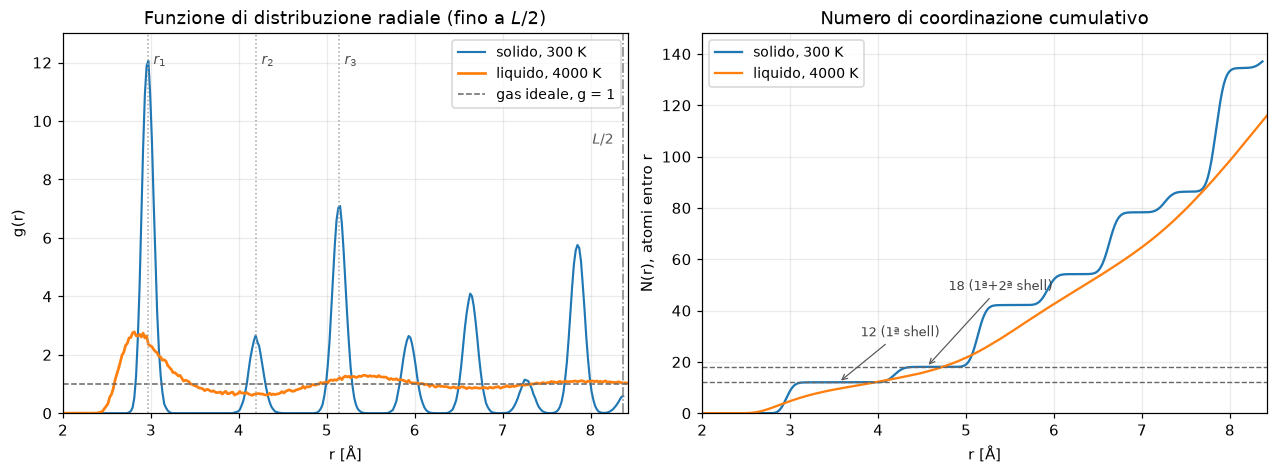

primo picco solido  : r = 2.970 Å   (r1 = 2.968 Å)
primo picco liquido : r = 2.810 Å
coordinazione entro 3.4 Å (solido) = 12.05 (atteso 12)
g(r) liquido a 6-8 Å = 0.97 (gas ideale: 1); nel solido i picchi non si smorzano, è un cristallo


In [3]:
pos_s, box_s = lattice(4)
solid = run(pos_s, box_s, 300.0, nsteps=1200, sample_every=20)

a_liq = A_LJ * (1.0 / 0.85) ** (1.0 / 3.0)
pos_l, box_l = lattice(4, a_liq)
liquid = run(pos_l, box_l, 4000.0, nsteps=1500, sample_every=20)

dr = 0.02
nbins_s = int(np.min(box_s) / 2.0 / dr)  # g(r) valida fino a L/2 (minima immagine)
nbins_l = int(np.min(box_l) / 2.0 / dr)
r_s, g_s = radial_distribution(solid["frames"][20:], box_s, nbins=nbins_s, dr=dr)
r_l, g_l = radial_distribution(liquid["frames"][25:], box_l, nbins=nbins_l, dr=dr)

rho_s = len(pos_s) / np.prod(box_s)
rho_l = len(pos_l) / np.prod(box_l)
n_s = np.cumsum(4.0 * np.pi * rho_s * g_s * r_s**2 * dr)
n_l = np.cumsum(4.0 * np.pi * rho_l * g_l * r_l**2 * dr)

r1, r2, r3 = A_LJ / np.sqrt(2.0), A_LJ, A_LJ * np.sqrt(1.5)
rmax = float(min(r_s[-1], r_l[-1]))  # L/2: oltre la minima immagine g(r) non è affidabile

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)

# Scala lineare: mostra tutti i picchi fino a L/2 (g = 0 incluso, senza tagli o buchi)
ax0.plot(r_s, g_s, lw=1.4, label="solido, 300 K")
ax0.plot(r_l, g_l, lw=1.8, label="liquido, 4000 K")
ax0.axhline(1.0, color="0.4", ls="--", lw=1, label="gas ideale, g = 1")
for rk, lab in ((r1, "$r_1$"), (r2, "$r_2$"), (r3, "$r_3$")):
    ax0.axvline(rk, color="0.65", ls=":", lw=1)
    ax0.text(rk + 0.06, 12.3, lab, ha="left", va="top", fontsize=9, color="0.3")
ax0.axvline(rmax, color="0.5", ls="-.", lw=1)
ax0.text(rmax - 0.1, 9.2, "$L/2$", ha="right", fontsize=9, color="0.35")
ax0.set(xlim=(2.0, rmax + 0.05), ylim=(0.0, 13.0), xlabel="r [Å]",
        ylabel="g(r)", title="Funzione di distribuzione radiale (fino a $L/2$)")
ax0.legend(loc="upper right", fontsize=9)

ax1.plot(r_s, n_s, lw=1.5, label="solido, 300 K")
ax1.plot(r_l, n_l, lw=1.5, label="liquido, 4000 K")
for n_shell, lab in ((12, "12 (1ª shell)"), (18, "18 (1ª+2ª shell)")):
    ax1.axhline(n_shell, color="0.4", ls="--", lw=0.9)
ax1.annotate("12 (1ª shell)", xy=(3.55, 12), xytext=(3.8, 30),
             arrowprops=dict(arrowstyle="->", lw=0.8, color="0.35"),
             fontsize=8.5, color="0.25")
ax1.annotate("18 (1ª+2ª shell)", xy=(4.55, 18), xytext=(4.8, 48),
             arrowprops=dict(arrowstyle="->", lw=0.8, color="0.35"),
             fontsize=8.5, color="0.25")
ax1.set(xlim=(2.0, rmax + 0.05), ylim=(0, 1.08 * max(n_s.max(), n_l.max())),
        xlabel="r [Å]", ylabel="N(r), atomi entro r",
        title="Numero di coordinazione cumulativo")
ax1.legend(loc="upper left", fontsize=9)

plt.show()

n_first_shell = float(np.interp(3.4, r_s, n_s))
i_pk = int(np.argmax(g_s[:170]))
print(f"primo picco solido  : r = {r_s[i_pk]:.3f} Å   (r1 = {r1:.3f} Å)")
print(f"primo picco liquido : r = {r_l[np.argmax(g_l[:170])]:.3f} Å")
print(f"coordinazione entro 3.4 Å (solido) = {n_first_shell:.2f} (atteso 12)")
print(f"g(r) liquido a 6-8 Å = {g_l[(r_l > 6) & (r_l < 8)].mean():.2f} "
      f"(gas ideale: 1); nel solido i picchi non si smorzano, è un cristallo")


**Lettura.** Nel solido $N(r)$ sale a gradini netti: dopo il primo picco
vale $\approx12$ (prima shell FCC), poi 18 (12+6 secondi vicini), 42 (+24 terzi
vicini), e così via; tutti i picchi di $g(r)$ sono visibili per intero fino a
$L/2=8.4$ Å (limite di validità della minima immagine) e tra le prime shell
$g(r)$ scende a zero. Nel liquido resta un primo picco largo seguito da
oscillazioni smorzate attorno a $g=1$, e $N(r)$ cresce in modo liscio senza
gradini (ordine solo locale).


## Esercizio 2 — equipartizione e fluttuazioni di $T$

**Cosa misura.** La temperatura istantanea è $T=2K/(3Nk_B)$: una media su
$3N$ termini quadratici indipendenti. Per il teorema del limite centrale la
sua fluttuazione relativa vale

$$
\frac{\delta T}{\langle T\rangle}\sim\frac{1}{\sqrt{N}},
$$

non $1/N$: raddoppiare $N$ riduce il rumore solo di $\sqrt2$. Nel limite
termodinamico $\delta T/T\to0$ e gli ensemble diventano equivalenti.

**Perché serve scartare il transiente.** Le velocità iniziali sono a
$T_\text{ini}=1200$ K; il sistema rilassa a $\langle T\rangle\approx600$ K in
frazioni di ps. Le prime cento righe non sono equilibrio e vanno escluse.

**Perché più semi.** $\delta T$ è una deviazione standard: con una sola
traiettoria corta il suo valore ha un errore statistico grande. Qui si
ripetono 3 seed indipendenti per ogni taglia e si riporta media $\pm$ errore
standard (barre nel grafico).


   N   <T> [K]    dT/<T>   errore
 108     603.2    0.0903   0.0080
 256     603.9    0.0652   0.0028
 500     603.7    0.0405   0.0036
 864     604.8    0.0301   0.0009
pendenza log-log = -0.54 (atteso -0.50)


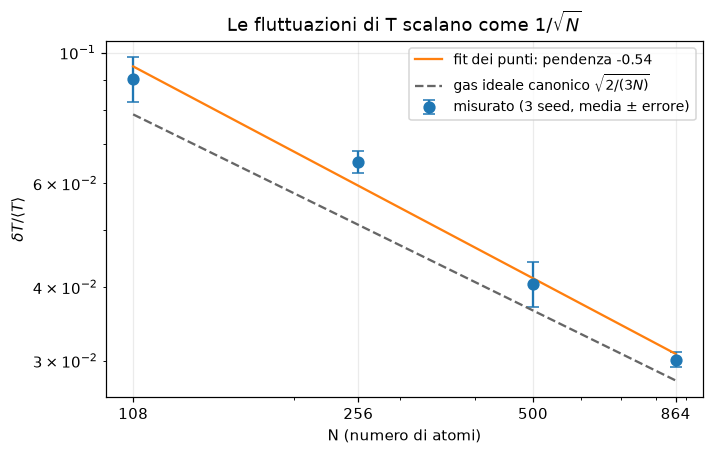

In [4]:
seeds = (33282739, 20260101, 555000111)
rows = []
for ncells in (3, 4, 5, 6):
    pos, box = lattice(ncells)
    values = []
    for seed in seeds:
        res = run(pos, box, 600.0, nsteps=400, sample_every=400, seed=seed)
        t = res["T"][100:]  # scarta il transiente
        values.append((t.std() / t.mean(), t.mean()))
    vals = np.array(values)
    rows.append((len(pos), vals[:, 1].mean(), vals[:, 0].mean(), vals[:, 0].std() / np.sqrt(len(values))))

arr = np.array(rows)
print(f"{'N':>4} {'<T> [K]':>9} {'dT/<T>':>9} {'errore':>8}")
for n, t_mean, dtr, err in rows:
    print(f"{n:4d} {t_mean:9.1f} {dtr:9.4f} {err:8.4f}")

coef2 = np.polyfit(np.log(arr[:, 0]), np.log(arr[:, 2]), 1)
slope = coef2[0]
n_fit = np.geomspace(arr[:, 0].min(), arr[:, 0].max(), 100)
print(f"pendenza log-log = {slope:.2f} (atteso -0.50)")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.set_xscale("log")
ax.set_yscale("log")
ax.errorbar(arr[:, 0], arr[:, 2], yerr=arr[:, 3], fmt="o", ms=7, capsize=4,
            label=r"misurato (3 seed, media $\pm$ errore)")
ax.plot(n_fit, np.exp(np.polyval(coef2, np.log(n_fit))), "-",
        color="C1", label=rf"fit dei punti: pendenza {slope:.2f}")
ax.plot(n_fit, np.sqrt(2.0 / (3.0 * n_fit)), "--", color="0.4",
        label=r"gas ideale canonico $\sqrt{2/(3N)}$")
ax.set_xticks(arr[:, 0].astype(int))
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(xlabel="N (numero di atomi)", ylabel=r"$\delta T/\langle T\rangle$",
       title="Le fluttuazioni di T scalano come $1/\\sqrt{N}$")
ax.legend(fontsize=9)
plt.show()


**Lettura.** $\langle T\rangle\approx600$ K per tutte le taglie: la regola
$T_\text{ini}=2T_\text{bersaglio}$ funziona. I punti stanno leggermente sopra
la curva teorica $\sqrt{2/(3N)}$ (il prefattore esatto dipende dall'ensemble
e dal potenziale), ma la pendenza è quella: $-1/2$ entro l'errore
statistico. In scala log-log una legge di potenza è una retta, quindi è il
test più diretto.


## Esercizio 3 — taglio netto vs raccordo polinomiale

**Cosa misura.** L'energia totale $E=K+\phi$ in NVE. Con il taglio netto
$\phi$ vale $\phi_{LJ}(r_c)\neq0$ fino a $r_c^-$ e zero appena oltre: ogni
volta che una coppia attraversa il cutoff l'energia cambia di un salto
$\Delta\phi=\phi_{LJ}(r_c)$ (qui $\approx-54$ meV), **senza alcun lavoro
esterno**. Le forze hanno una delta di Dirac in $r_c$. È un difetto del
**modello**, non dell'integratore: $\Delta t\to0$ non lo elimina.

Con il raccordo, $\phi$ e $\phi'$ sono continue a $r_c$: il salto è nullo a
meno dell'errore di macchina e resta solo l'errore di troncamento di Verlet,
che invece scala con $\Delta t$ (esercizio 4).


deltaE/|E|  taglio netto = 2.32e-04
deltaE/|E|  raccordo     = 8.34e-06   (rapporto 28x)
salto di potenziale a r_c (taglio netto) = -54.4 meV


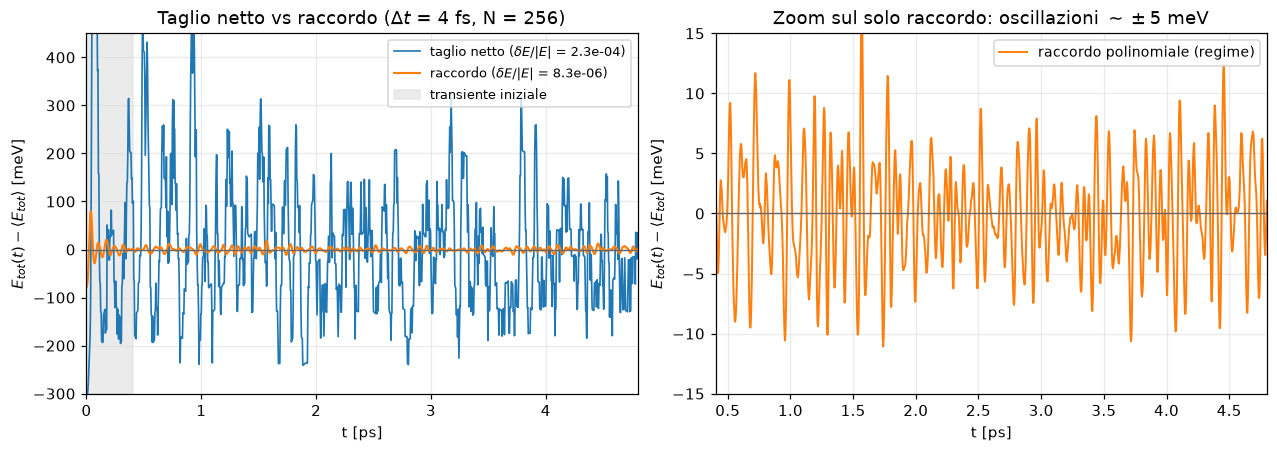

In [5]:
pos, box = lattice(4)
sharp = run(pos, box, 600.0, dt_fs=4.0, nsteps=1200, sample_every=1200, smooth=False)
smooth = run(pos, box, 600.0, dt_fs=4.0, nsteps=1200, sample_every=1200, smooth=True)

ntherm = 100
dE_sharp = dE_over_E(sharp, ntherm=ntherm)
dE_smooth = dE_over_E(smooth, ntherm=ntherm)
e_ref_sharp = float(sharp["etot"][ntherm:].mean())
e_ref_smooth = float(smooth["etot"][ntherm:].mean())
print(f"deltaE/|E|  taglio netto = {dE_sharp:.2e}")
print(f"deltaE/|E|  raccordo     = {dE_smooth:.2e}   (rapporto {dE_sharp / dE_smooth:.0f}x)")
print(f"salto di potenziale a r_c (taglio netto) = {lennard_jones_pair(RC, SIGMA, EPSILON) * 1e3:.1f} meV")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11.5, 4.0), constrained_layout=True)

t_ps = sharp["time_ps"]
ax0.plot(t_ps, (sharp["etot"] - e_ref_sharp) * 1e3, lw=1.1,
         label=f"taglio netto ($\\delta E/|E|$ = {dE_sharp:.1e})")
ax0.plot(t_ps, (smooth["etot"] - e_ref_smooth) * 1e3, lw=1.4,
         label=f"raccordo ($\\delta E/|E|$ = {dE_smooth:.1e})")
ax0.axvspan(0, t_ps[ntherm], color="0.85", alpha=0.5, label="transiente iniziale")
ax0.axhline(0.0, color="0.4", lw=0.9)
ax0.set(xlim=(0, t_ps[-1]), ylim=(-300, 450), xlabel="t [ps]",
        ylabel=r"$E_{tot}(t)-\langle E_{tot}\rangle$ [meV]",
        title="Taglio netto vs raccordo ($\\Delta t$ = 4 fs, N = 256)")
ax0.legend(loc="upper right", fontsize=8.5)

ax1.plot(t_ps[ntherm:], (smooth["etot"][ntherm:] - e_ref_smooth) * 1e3,
         lw=1.3, color="C1", label="raccordo polinomiale (regime)")
ax1.axhline(0.0, color="0.4", lw=0.9)
ax1.set(xlim=(t_ps[ntherm], t_ps[-1]), ylim=(-15, 15), xlabel="t [ps]",
        ylabel=r"$E_{tot}(t)-\langle E_{tot}\rangle$ [meV]",
        title="Zoom sul solo raccordo: oscillazioni $\\sim \\pm 5$ meV")
ax1.legend(loc="upper right", fontsize=9)

plt.show()


**Lettura.** Riferendo l'energia alla media dopo il transiente iniziale
(fascia grigia), il taglio netto compie escursioni di centinaia di meV perché
ogni attraversamento di $r_c$ inietta o sottrae $\Delta\phi\approx-54$ meV. Con
il raccordo polinomiale (pannello destro) l'energia oscilla attorno alla media
entro $\pm 5$ meV senza deriva: ciò che resta è il solo errore di troncamento
di *velocity Verlet*.


## Esercizio 4 — scansione del passo temporale

**Cosa misura.** L'errore di troncamento di *velocity Verlet* per passo è
$\mathcal{O}(\Delta t^3)$ sulle velocità e $\mathcal{O}(\Delta t^4)$ sulle
posizioni; la deriva di energia su tempi brevi scala circa come
$\Delta t^2$. Il criterio operativo è

$$
\frac{\delta E}{|\langle E\rangle|}\le10^{-5}.
$$

**Attenzione al confronto corretto.** Se si tengono fissi i *passi* e si
cambia $\Delta t$, si simulano tempi fisici diversi e il confronto è
inquinato. Qui si fissa la **durata** ($1.6$ ps) e si cambia il numero di
passi: così l'unica variabile è $\Delta t$.


T =  300 K: 1 fs -> 3.8e-07  2 fs -> 1.5e-06  4 fs -> 6.1e-06  8 fs -> 2.5e-05
           massimo dt conforme: 4.0 fs


T = 1500 K: 1 fs -> 1.8e-06  2 fs -> 7.2e-06  4 fs -> 2.8e-05  8 fs -> 1.1e-04
           massimo dt conforme: 2.0 fs


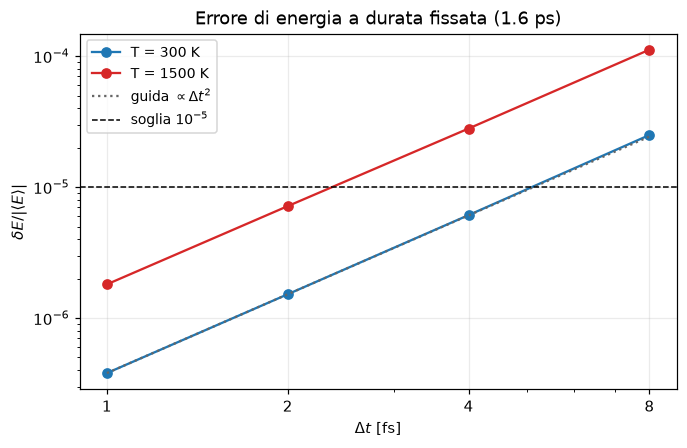

In [6]:
pos, box = lattice(4)
t_end = 1.6e-12  # s
dts = [1.0, 2.0, 4.0, 8.0]
scan = {}
for t_target in (300.0, 1500.0):
    values = []
    for dt_fs in dts:
        nsteps = int(round(t_end / (dt_fs * FS)))
        res = run(pos, box, t_target, dt_fs=dt_fs, nsteps=nsteps,
                  sample_every=nsteps)
        values.append(dE_over_E(res, ntherm=nsteps // 4))
    scan[t_target] = values
    allowed = [dt for dt, v in zip(dts, values) if v <= 1e-5]
    print(f"T = {t_target:4.0f} K: " + "  ".join(f"{dt:.0f} fs -> {v:.1e}" for dt, v in zip(dts, values)))
    print(f"           massimo dt conforme: {max(allowed) if allowed else None} fs")

colors = {300.0: "C0", 1500.0: "C3"}
fig, ax = plt.subplots(figsize=(7, 4.2))
for t_target, values in scan.items():
    ax.loglog(dts, values, "o-", ms=6, color=colors[t_target], label=f"T = {t_target:.0f} K")
ax.loglog(dts, np.asarray(scan[300.0])[0] * (np.array(dts) / dts[0]) ** 2, ":",
          color="0.4", lw=1.5, label=r"guida $\propto\Delta t^2$")
ax.axhline(1e-5, color="k", ls="--", lw=1, label=r"soglia $10^{-5}$")
ax.set_xticks(dts)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(xlabel=r"$\Delta t$ [fs]", ylabel=r"$\delta E/|\langle E\rangle|$",
       title="Errore di energia a durata fissata (1.6 ps)")
ax.legend(fontsize=9, loc="upper left")
plt.show()


**Lettura.** I punti seguono la guida $\Delta t^2$ su quasi due decadi: è
la firma dell'integratore. A 1500 K la curva è spostata in alto: a parità di
$\Delta t$ gli atomi percorrono più spazio e il potenziale viene esplorato
peggio, quindi il passo ammesso è più piccolo. Il $\Delta t$ va scelto **alla
temperatura di lavoro**, non a una temperatura qualsiasi.


## Esercizio 5 — cluster vs bulk (PBC)

**Cosa misura.** L'energia per atomo $\mu=E/N$. In un cluster una frazione
$f_s$ di atomi sta in superficie ed è sotto-coordinata; per un oggetto
compatto $f_s\propto N^{-1/3}$, quindi

$$
\mu(N)\simeq\mu_\text{bulk}+\frac{\gamma}{N^{1/3}},
$$

con $\gamma>0$ coefficiente che racchiude l'energia di superficie (il conto
per una sfera dà $\gamma\propto\gamma_s$, energia per unità di area).
La convergenza al bulk è **lenta**: per $f_s\to0$ servono migliaia di atomi.
Con le PBC non c'è superficie: una cella con $L>2r_c$ dà subito
$\mu_\text{bulk}$, indipendente da $N$.

**Come si rilassa.** *Steepest descent*: $\mathbf r_i\leftarrow
\mathbf r_i+C\mathbf F_i$, con $C$ adattivo (cresce se $\phi$ scende, dimezza
se sale) e arresto su $F_\text{max}<10^{-3}$ eV/Å.


   N   cluster E/N      Fmax   bulk E/N      Fmax
 108       -1.5820  6.92e-04    -2.2465  2.79e-14
 256       -1.7467  7.34e-04    -2.2465  2.98e-14
 500       -1.8487  8.66e-04    -2.2465  4.22e-14
 864       -1.9182  9.75e-04    -2.2465  4.43e-14


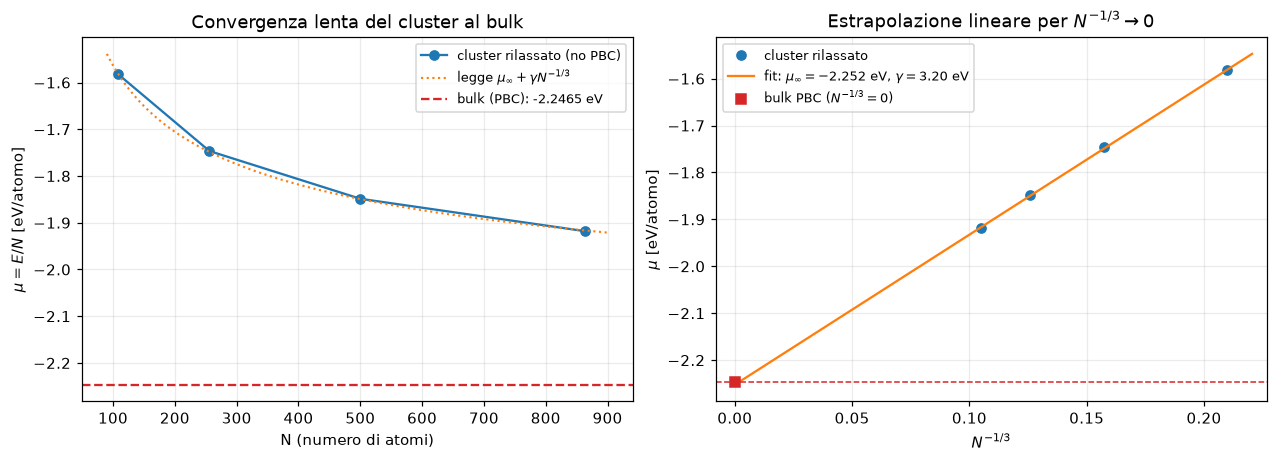

mu_bulk (PBC) = -2.2465 eV/atomo
fit cluster: mu_inf = -2.2523 eV/atomo, gamma = 3.198 eV
formula 12+6 vicini con LJ puro = -2.313 eV/atomo


In [7]:
def steepest_descent(pos, box, *, c0=5e-3, ftol=1e-3, max_iter=400):
    """Discesa lungo il gradiente con passo C adattivo; box=None = cluster."""
    pos = pos.copy()
    coeff = c0
    for _ in range(max_iter):
        f = forces(pos, box)
        fmax = float(np.linalg.norm(f, axis=1).max())
        if fmax < ftol:
            break
        e = energy(pos, box)
        trial = pos + coeff * f
        if energy(trial, box) < e:
            pos, coeff = trial, 1.1 * coeff
        else:
            coeff *= 0.5
    f = forces(pos, box)
    return pos, energy(pos, box), float(np.linalg.norm(f, axis=1).max())


size_cells = (3, 4, 5, 6)
cluster, bulk = [], []
for ncells in size_cells:
    pos, box = lattice(ncells)
    e0 = energy(pos, None)
    _, e_c, f_c = steepest_descent(pos, None)
    cluster.append((len(pos), e_c / len(pos), f_c, e0 / len(pos)))
    _, e_b, f_b = steepest_descent(pos, box)
    bulk.append((len(pos), e_b / len(pos), f_b))

print(f"{'N':>4} {'cluster E/N':>13} {'Fmax':>9} {'bulk E/N':>10} {'Fmax':>9}")
for c, b in zip(cluster, bulk):
    print(f"{c[0]:4d} {c[1]:13.4f} {c[2]:9.2e} {b[1]:10.4f} {b[2]:9.2e}")

n_arr = np.array([c[0] for c in cluster])
mu_clu = np.array([c[1] for c in cluster])
mu_bulk = float(np.mean([b[1] for b in bulk]))

coef = np.polyfit(n_arr ** (-1.0 / 3.0), mu_clu, 1)
x_inv = n_arr ** (-1.0 / 3.0)
x_line = np.linspace(0.0, x_inv.max() * 1.05, 100)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11.5, 4.1), constrained_layout=True)

n_smooth = np.linspace(90, 900, 200)
ax0.plot(n_arr, mu_clu, "o-", ms=6, label="cluster rilassato (no PBC)")
ax0.plot(n_smooth, np.polyval(coef, n_smooth ** (-1.0 / 3.0)), ":", color="C1",
         lw=1.4, label=r"legge $\mu_\infty+\gamma N^{-1/3}$")
ax0.axhline(mu_bulk, color="C3", ls="--", label=f"bulk (PBC): {mu_bulk:.4f} eV")
ax0.set(xlabel="N (numero di atomi)", ylabel=r"$\mu=E/N$ [eV/atomo]",
        title="Convergenza lenta del cluster al bulk")
ax0.legend(fontsize=8.5, loc="upper right")

ax1.plot(x_inv, mu_clu, "o", ms=6, label="cluster rilassato")
ax1.plot(x_line, np.polyval(coef, x_line), "-", color="C1",
         label=rf"fit: $\mu_\infty={coef[1]:.3f}$ eV, $\gamma={coef[0]:.2f}$ eV")
ax1.plot(0.0, mu_bulk, "s", ms=7, color="C3", label=r"bulk PBC ($N^{-1/3}=0$)")
ax1.axhline(mu_bulk, color="C3", ls="--", lw=1)
ax1.set(xlim=(-0.008, x_inv.max() * 1.08), xlabel=r"$N^{-1/3}$",
        ylabel=r"$\mu$ [eV/atomo]",
        title=r"Estrapolazione lineare per $N^{-1/3}\to 0$")
ax1.legend(fontsize=8.5, loc="upper left")

plt.show()

print(f"mu_bulk (PBC) = {mu_bulk:.4f} eV/atomo")
print(f"fit cluster: mu_inf = {coef[1]:.4f} eV/atomo, gamma = {coef[0]:.3f} eV")
print(f"formula 12+6 vicini con LJ puro = {0.5 * (12 * lennard_jones_pair(A_LJ / np.sqrt(2), SIGMA, EPSILON) + 6 * lennard_jones_pair(A_LJ, SIGMA, EPSILON)):.3f} eV/atomo")


**Lettura.** Il cluster parte da $\mu\approx-1.58$ eV/atomo e scende
lentamente; in funzione di $N^{-1/3}$ i punti sono quasi allineati, come
previsto dall'energia di superficie. L'intercetta del fit,
$\mu_\infty\approx-2.25$ eV/atomo, cade entro pochi meV dal valore bulk: la
legge $N^{-1/3}$ descrive bene i dati. Il bulk con PBC dà $\mu=-2.2465$
eV/atomo per tutte le taglie ammesse ($L>2r_c$) e non ha superficie da
pagare.

**Perché non $-2.32$?** La formula $12+6$ vicini con LJ puro dà
$-2.31$ eV/atomo. Qui $a=a_0=4.197$ Å mette i secondi vicini ($r_2=4.20$ Å)
nella coda raccordata tra $4.0$ e $4.5$ Å, che ne riduce l'attrazione: da qui
$-2.2465$. Il confronto cluster–bulk resta valido perché usa lo stesso
potenziale per entrambi (e il codice del progetto usa un raccordo **cubico**;
la variante $P_7$ del capitolo impone anche $\phi^{\prime\prime}$ e $\phi^{\prime\prime\prime}$ continue e
non cambia la conclusione).


In [8]:
# --- controlli finali (riproducibili: seed fissi) ---
assert abs(r_s[i_pk] - r1) < 0.1, "primo picco g(r) lontano da r1"
assert 11.0 < n_first_shell < 13.0, "coordinazione del solido diversa da 12"
assert slope < -0.35, "scaling di deltaT/T non compatibile con 1/sqrt(N)"
assert dE_sharp > 10 * dE_smooth, "il taglio netto dovrebbe conservare molto peggio"
assert max(c[2] for c in cluster) < 1e-2, "steepest descent non convergente"
assert mu_clu[0] > mu_clu[-1] > mu_bulk, "mu(N) del cluster deve scendere verso il bulk"
assert abs(coef[1] - mu_bulk) < 0.3, "estrapolazione del fit lontana dal bulk"
print("tutti i controlli superati")


tutti i controlli superati


## Riepilogo

| Esercizio | Risultato numerico |
|---|---|
| 1 | primo picco solido $r\approx2.97$ Å; 12 vicini entro 3.4 Å; liquido $g\to1$ |
| 2 | $\langle T\rangle\approx600$ K; pendenza log-log $\approx-1/2$ |
| 3 | $\delta E/\lvert E\rvert$: $\sim10^{-4}$ (netto) vs $\sim10^{-5}$ (raccordo) |
| 4 | guidato da $\Delta t^2$; $\Delta t$ ammesso più piccolo ad alta $T$ |
| 5 | cluster $\to$ bulk come $N^{-1/3}$; bulk PBC $-2.2465$ eV/atomo |
